# **1. Steg. Testa conversational AI Cybersecurity Assistant with Contextual Memory and self-adaptive database**
Log: admin1 Pass: 123

Log: admin2 Pass: 456

In [ ]:
# Install necessary packages
!pip install -q scikit-learn

# Import required libraries
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import os

# ======================
# 1. AUTHORIZED CREDENTIALS
# ======================

# Dictionary of authorized users and their passwords
authorized_users = {
    "admin1": "123",
    "admin2": "456"
}

# ======================
# 2. KNOWLEDGE BASE
# ======================

# Public knowledge base accessible to all users
public_db = {
    "password requirements": {
        "answer": "Our password policy requires at least 12 characters with a mix of uppercase, lowercase, numbers, and special symbols.",
        "followup": "Would you like me to suggest a strong password pattern?"
    },
    "report phishing": {
        "answer": "If you suspect an email is phishing, please forward it to phishing@company.com and then delete it from your inbox.",
        "followup": "Would you like to see examples of recent phishing attempts?"
    },
    "VPN policy": {
        "answer": "All remote access to company systems must use our approved VPN client.",
        "followup": "Need help setting up the VPN?"
    }
}

# Restricted knowledge base accessible only to authorized users
restricted_db = {
    "security breaches": {
        "answer": "[RESTRICTED] March 2024 Incident: Phishing attack compromised 2 employee accounts. All affected systems were isolated within 4 hours.",
        "followup": "Full report available to security team members."
    },
    "system vulnerabilities": {
        "answer": "[RESTRICTED] Critical Update: Patch CVE-2024-5678 in all Linux servers by Friday.",
        "followup": "Contact SOC for patching assistance."
    }
}

# ======================
# 3. AI SETUP
# ======================

# Combine all questions from both knowledge bases
all_questions = list(public_db.keys()) + list(restricted_db.keys())

# Initialize the TF-IDF vectorizer for better partial matches
vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(2,3))
vectorizer.fit(all_questions)

# ======================
# 4. CONVERSATIONAL MEMORY
# ======================

# List to store the conversation history
conversation_history = []

# ======================
# 5. LOGIN ATTEMPT LOGGING SETUP
# ======================

# Define the filename for logging login attempts
log_filename = 'login_attempts.csv'

# Check if the log file exists; if not, create it with headers
if not os.path.exists(log_filename):
    with open(log_filename, mode='w') as file:
        file.write('timestamp,username,password,success,attempt_number\n')

# Function to log each login attempt
def log_login_attempt(username, password, success, attempt_number):
    timestamp = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    with open(log_filename, mode='a') as file:
        file.write(f'{timestamp},{username},{password},{success},{attempt_number}\n')

# ======================
# 6. AI SEARCH FUNCTION
# ======================

# Function to retrieve answers based on user questions
def get_human_answer(question):
    # Vectorize the user's question
    question_vec = vectorizer.transform([question])

    # Calculate similarity scores with public knowledge base
    public_scores = cosine_similarity(
        question_vec,
        vectorizer.transform(public_db.keys())
    )
    best_public_idx = np.argmax(public_scores)
    best_public_score = public_scores[0, best_public_idx]

    # Calculate similarity scores with restricted knowledge base
    restricted_scores = cosine_similarity(
        question_vec,
        vectorizer.transform(restricted_db.keys())
    )
    best_restricted_idx = np.argmax(restricted_scores)
    best_restricted_score = restricted_scores[0, best_restricted_idx]

    print(f"\n[AI Analysis]")
    print(f"Public match: '{list(public_db.keys())[best_public_idx]}' ({best_public_score:.2f})")
    print(f"Restricted match: '{list(restricted_db.keys())[best_restricted_idx]}' ({best_restricted_score:.2f})")

    # Determine which knowledge base to use
    if best_public_score > 0.5 or best_public_score > best_restricted_score:
        print("[AI Decision] Using public database")
        topic = list(public_db.keys())[best_public_idx]
        result = public_db[topic]
        print("\n" + result["answer"])
        conversation_history.append({"role": "assistant", "content": result["answer"]})
        followup = input(result["followup"] + " (y/n): ").lower()
        if followup == 'y':
            followup_response = get_followup_response(topic)
            conversation_history.append({"role": "assistant", "content": followup_response})
            return followup_response
        return ""
    else:
        print("[AI Decision] Checking restricted content")
        max_attempts = 3
        for attempt in range(1, max_attempts + 1):
            username = input("Username: ").strip()
            password = input("Password: ").strip()
            if authorized_users.get(username) == password:
                log_login_attempt(username, password, True, attempt)
                topic = list(restricted_db.keys())[best_restricted_idx]
                result = restricted_db[topic]
                print("\n" + result["answer"])
                conversation_history.append({"role": "assistant", "content": result["answer"]})
                return result["followup"]
            else:
                print("ACCESS DENIED - Invalid credentials.")
                log_login_attempt(username, password, False, attempt)
        print("Too many failed attempts. Returning to main chat.")
        return ""

# Function to provide follow-up responses based on the topic
def get_followup_response(topic):
    if topic == "password requirements":
        return "\nTry this pattern: CompanyName@2024! (mix of name, year, and symbols)"
    elif topic == "report phishing":
        return "\nRecent phishing examples:\n1. Fake IT support emails\n2. 'Urgent' document sharing links"
    elif topic == "VPN policy":
        return "\nVPN setup guide sent to your email. Check spam folder if not received."
    return ""

# ======================
# 7. CONVERSATIONAL INTERFACE
# ======================

# Welcome message
print("🔐 Hi! I'm your Cybersecurity Assistant. How can I help?")
print("(Type 'quit' anytime to exit)\n")

# Main loop to interact with the user
while True:
    question = input("\nYour question: ").strip()
    if question.lower() in ['quit', 'exit']:
        print("Stay secure! Goodbye.")
        break

    # Add user input to conversation history
    conversation_history.append({"role": "user", "content": question})

    # Handle specific queries about passwords
    if "pass" in question.lower() and "requirement" not in question.lower():
        print("\nI noticed you asked about passwords. Did you mean:")
        print("1. Password requirements")
        print("2. How to create a strong password")
        choice = input("Please select (1/2): ")
        if choice == "1":
            question = "password requirements"
        elif choice == "2":
            response = (
                "\nHere's how to create strong passwords:\n"
                "- Use a memorable phrase like 'MyDogMax@2024!'\n"
                "- Never reuse passwords across sites\n"
                "- Consider using a password manager"
            )
            print(response)
            # Add AI response to conversation history
            conversation_history.append({"role": "assistant", "content": response})
            continue

    # Get and display the AI's response
    response = get_human_answer(question)
    if response:
        print(response)
        # Add AI response to conversation history
        conversation_history.append({"role": "assistant", "content": response})


🔐 Hi! I'm your Cybersecurity Assistant. How can I help?
(Type 'quit' anytime to exit)


Your question: vpn

[AI Analysis]
Public match: 'VPN policy' (0.61)
Restricted match: 'system vulnerabilities' (0.04)
[AI Decision] Using public database

All remote access to company systems must use our approved VPN client.
Need help setting up the VPN? (y/n): y

VPN setup guide sent to your email. Check spam folder if not received.

Your question: security

[AI Analysis]
Public match: 'VPN policy' (0.04)
Restricted match: 'security breaches' (0.72)
[AI Decision] Checking restricted content
Username: admin1
Password: 000
ACCESS DENIED - Invalid credentials.
Username: admin
Password: 999
ACCESS DENIED - Invalid credentials.
Username: admin1
Password: 123

[RESTRICTED] March 2024 Incident: Phishing attack compromised 2 employee accounts. All affected systems were isolated within 4 hours.
Full report available to security team members.

Your question: security

[AI Analysis]
Public match: 'VPN policy

# **Accessing the Log File in Google Colab:**

In [ ]:
from google.colab import files
files.download('login_attempts.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Result:**

timestamp,username,password,success,attempt_number

2025-05-15 07:45:17,admin1,000,False,1

2025-05-15 07:45:22,admin,999,False,2

2025-05-15 07:45:27,admin1,123,True,3

2025-05-15 07:45:36,adm,admin,False,1

2025-05-15 07:45:48,admin2,456,True,2

2025-05-15 07:45:57,d,a,False,1

2025-05-15 07:46:05,admi,2,False,2

2025-05-15 07:46:10,admin,2,False,3

2025-05-15 07:46:22,admin2,456,True,1

# **Login attempts dataset generation**
(optional)

In [ ]:
import csv
import random
from datetime import datetime, timedelta
import pandas as pd
from google.colab import files

# Configuration Parameters
NUM_ENTRIES = 100000
START_DATE = datetime(2025, 1, 1, 0, 0, 0)
TIME_SPAN_DAYS = 30
MAX_ATTEMPTS_PER_USER = 3

# Correct credentials - these will be the only combinations that return True
CORRECT_CREDENTIALS = {
    'admin1': '123',
    'admin2': '456'
}

# Helper Functions
def generate_random_timestamp(start_date, span_days):
    random_seconds = random.randint(0, span_days * 24 * 60 * 60)
    return start_date + timedelta(seconds=random_seconds)

def generate_username(user_id):
    # 20% chance to be an admin user (to get more True values)
    if random.random() < 0.20:
        return random.choice(list(CORRECT_CREDENTIALS.keys()))
    return f"user{user_id}"

def generate_password(username, attempt_number):
    """Generate password with high probability of being correct for admin users"""
    if username in CORRECT_CREDENTIALS:
        # 80% chance to return correct password for admin users
        if random.random() < 0.80:
            return CORRECT_CREDENTIALS[username]
        else:
            # Incorrect password but similar format
            return ''.join(random.choices('123456789', k=3))
    else:
        # Always incorrect password for non-admin users
        return ''.join(random.choices('abcdefghijklmnopqrstuvwxyz0123456789', k=6))

# Data Generation
data = []
user_attempts = {}

# We'll create a pool of users with more admin users to get more True values
total_users = NUM_ENTRIES // MAX_ATTEMPTS_PER_USER
admin_users_count = int(total_users * 0.20)  # 20% admin users
regular_users_count = total_users - admin_users_count

# Create user IDs - first create admin users, then regular users
user_ids = []
for i in range(1, admin_users_count + 1):
    user_ids.append(f"admin{i%2 + 1}")  # Alternates between admin1 and admin2

for i in range(1, regular_users_count + 1):
    user_ids.append(f"user{i}")

# Shuffle and distribute attempts
random.shuffle(user_ids)
user_attempts_list = user_ids * MAX_ATTEMPTS_PER_USER
random.shuffle(user_attempts_list)

entries_generated = 0
for username in user_attempts_list[:NUM_ENTRIES]:
    attempt_number = user_attempts.get(username, 0) + 1
    password = generate_password(username, attempt_number)
    success = (username in CORRECT_CREDENTIALS) and (password == CORRECT_CREDENTIALS[username])
    timestamp = generate_random_timestamp(START_DATE, TIME_SPAN_DAYS).strftime('%Y-%m-%d %H:%M:%S')
    user_attempts[username] = attempt_number

    data.append([timestamp, username, password, success, attempt_number])
    entries_generated += 1

# Save to CSV
filename = 'login_attempts_dataset.csv'
with open(filename, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['timestamp', 'username', 'password', 'success', 'attempt_number'])
    writer.writerows(data)

print(f"✅ Synthetic dataset '{filename}' generated successfully with {entries_generated} entries.")

# Display Sample Data
df = pd.read_csv(filename)
print("\n📄 Sample Data:")
print(df.head(20))  # Show more rows to see True values

# Calculate statistics
success_count = df['success'].sum()
total_entries = len(df)
success_rate = success_count / total_entries

print(f"\n📊 Statistics:")
print(f"Total entries: {total_entries}")
print(f"True values: {success_count} ({success_rate:.2%})")
print(f"False values: {total_entries - success_count} ({(1 - success_rate):.2%})")

# Show admin attempts
admin_attempts = df[df['username'].isin(CORRECT_CREDENTIALS.keys())]
admin_success_rate = admin_attempts['success'].mean()
print(f"\n🔑 Admin attempts: {len(admin_attempts)}")
print(f"Admin success rate: {admin_success_rate:.2%}")

# Provide Download Link
files.download(filename)

✅ Synthetic dataset 'login_attempts_dataset.csv' generated successfully with 99999 entries.

📄 Sample Data:
              timestamp   username password  success  attempt_number
0   2025-01-06 13:24:47     admin2      456     True               1
1   2025-01-01 12:43:38  user13455   3hv9m2    False               1
2   2025-01-18 11:22:10   user5636   dzlmxp    False               1
3   2025-01-09 01:40:47  user12425   bsd2pb    False               1
4   2025-01-21 21:48:59  user14121   7knwze    False               1
5   2025-01-07 16:07:39  user19543   hpbvzw    False               1
6   2025-01-19 20:50:32     admin1      123     True               1
7   2025-01-17 01:08:10  user15435   vcir31    False               1
8   2025-01-03 09:02:15  user26615   fu3xmn    False               1
9   2025-01-23 23:44:25     admin1      123     True               2
10  2025-01-18 23:28:19     admin1      123     True               3
11  2025-01-10 07:27:55  user23160   piawju    False            

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Steg 2. Unsupervised Log Anomaly Detection Using the XGBoost**

**Step 1: Upload and Preprocess the Data**

In [ ]:
# Upload CSV File
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Encode categorical variables
from sklearn.preprocessing import LabelEncoder
label_encoders = {}
for column in ['username', 'password']:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column])
    label_encoders[column] = le

# Convert 'timestamp' to datetime and extract features
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day'] = df['timestamp'].dt.day
df['month'] = df['timestamp'].dt.month
df['weekday'] = df['timestamp'].dt.weekday

# Drop the original 'timestamp' column
df.drop('timestamp', axis=1, inplace=True)

# Define features for the model
features = ['username', 'password', 'attempt_number', 'hour', 'day', 'month', 'weekday']

# Check if 'success' column exists
if 'success' in df.columns:
    # Convert 'success' to binary labels: True -> 0 (Normal), False -> 1 (Anomaly)
    df['true_label'] = df['success'].apply(lambda x: 0 if x else 1)
else:
    print("The 'success' column is missing from the dataset. Cannot proceed with supervised training.")


Saving login_attempts_dataset.csv to login_attempts_dataset (16).csv


**Step 2: Train XGBoost Model**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
y = df['true_label']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train the XGBoost classifier
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
model.fit(X_train, y_train)

# Predict anomalies
df['anomaly'] = model.predict(X_scaled)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:57:38] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


**Step 3: Evaluate Model Performance**

Accuracy: 1.00
Precision: 1.00
Recall: 1.00
F1-Score: 1.00


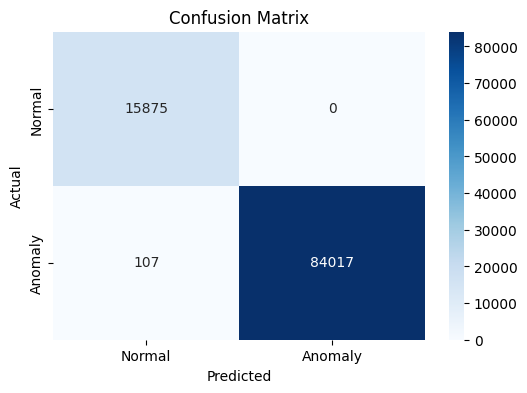

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate evaluation metrics
accuracy = accuracy_score(df['true_label'], df['anomaly'])
precision = precision_score(df['true_label'], df['anomaly'])
recall = recall_score(df['true_label'], df['anomaly'])
f1 = f1_score(df['true_label'], df['anomaly'])

# Display metrics
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")

# Confusion Matrix
cm = confusion_matrix(df['true_label'], df['anomaly'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


**Step 4: Visualizations**

Visualization 1: Time-series plot of anomalies

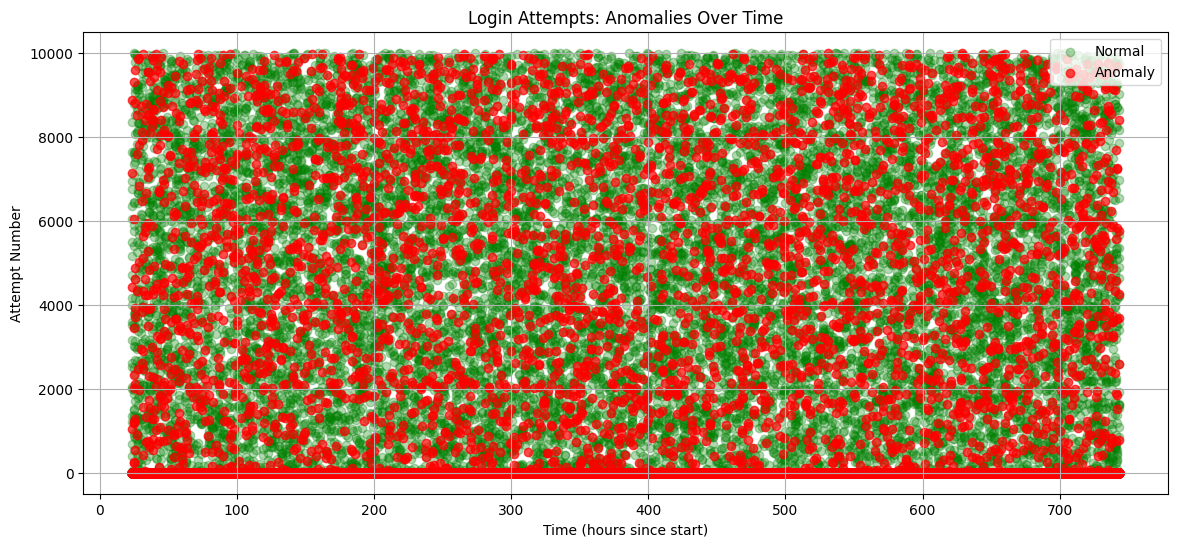

In [ ]:
import matplotlib.pyplot as plt

# Create a datetime index for plotting (using hour-level granularity)
df['time_group'] = df['hour'] + df['day']*24  # Simple hour-based grouping

# Plot normal points
normal = df[df['anomaly'] == 0]
plt.figure(figsize=(14, 6))
plt.scatter(normal['time_group'], normal['attempt_number'],
            c='green', alpha=0.3, label='Normal')

# Plot anomalies
anomalies = df[df['anomaly'] == 1]
plt.scatter(anomalies['time_group'], anomalies['attempt_number'],
            c='red', alpha=0.7, label='Anomaly')

plt.title('Login Attempts: Anomalies Over Time')
plt.xlabel('Time (hours since start)')
plt.ylabel('Attempt Number')
plt.legend()
plt.grid(True)
plt.show()


**Visualization 2: Feature importance for anomalies**

<ipython-input-94-9bd55ed7532e>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


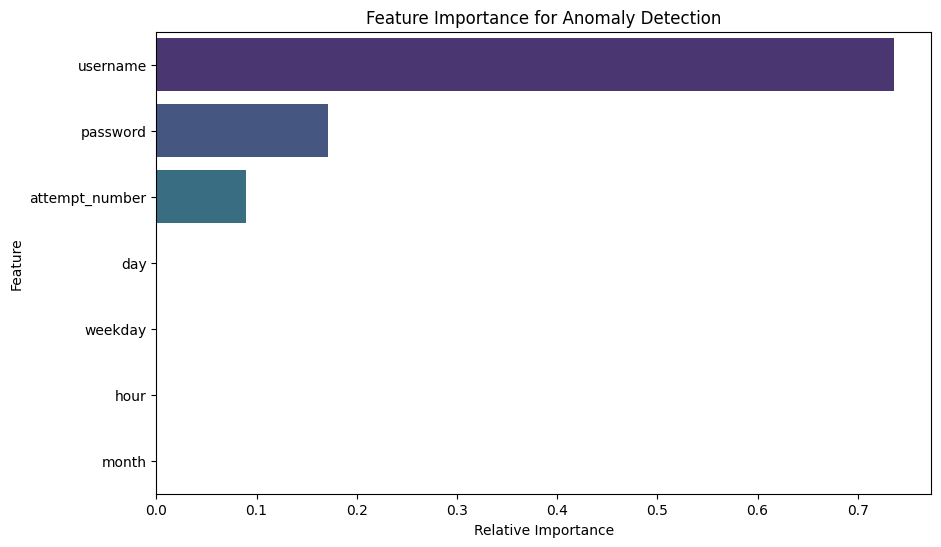

In [ ]:
import seaborn as sns
import numpy as np

plt.figure(figsize=(10, 6))

# Get feature importance from the XGBoost model
feature_importance = model.feature_importances_

# Create DataFrame for visualization
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': feature_importance
}).sort_values('Importance', ascending=False)

# Plot
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Feature Importance for Anomaly Detection')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()


**Perfect Cross-Validation Accuracy (1.00):**

The model achieved 100% accuracy across all 5 folds of cross-validation.

This means it generalizes extremely well to different subsets of your training data.

Zero Standard Deviation (± 0.00):

There was no variability in performance across folds.

This suggests the model is extremely stable and not sensitive to how the data is split.

In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(best_model, X_train[:, selector.support_], y_train, cv=5)
print(f"CV Accuracy: {scores.mean():.2f} ± {scores.std():.2f}")

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [12:15:08] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [12:15:10] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [12:15:11] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [12:15:15] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [12:15:16] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_e

CV Accuracy: 1.00 ± 0.00
